# Przygotowanie danych i nauka modelu

## Dane
Mamy do czynienia z zbiorem 569 próbek, z czego 212 dotyczy nowotworu złośliwego (0), a 357 nowotworu łagodnego (1).

Dane dzielimy w stosunku 80:20 dla zbioru treningowego i testowego. Nie tworzymy zbioru walidacyjnego, ponieważ jest on tworzony w walidacji krzyżowej. Stosujemy stratify=y, aby zachować zbliżone proporcje klas w obu zbiorach. 

## Walidacja krzyżowa 
Walidacja służy do podjęcia decyzji jaki model wybrać, jakich hiperparametrów użyć, ile cech zachować. Test służy do sprawdzenia już podjętych decyzji na próbkach, których nie wykorzystywaliśmy podczas wyboru.

Walidacja krzyżowa pozwala nam bardziej wiarygodnie oszacować jakość modelu bez uzależnienia wyniku od jednego zbioru danych, tak jak by miało to miejsce przy zwykłej walidacji (ponieważ np w zbiorze walidacyjnym mogłyby się znaleźć łatwe próbki). W tym przypadku mamy 5 foldów (cv=5). Zamiast jednego podziału dzielimy 455 próbek (80% z zbioru treningowego) na pięć części (foldów). W każdej iteracji model trenujemy na 80% próbach z tego zbioru, a następnie oceniamy na 20% próbkach. Za każdym razem dopasowujemy nowy model. W każdym takim foldzie od nowa dopasowujemy nie tylko klasyfikator, ale także selekcję cech i skalowanie, dzięki umieszczeniu tych operacji w pipeline. Zapobiega to data leakage z części walidacyjnej. Po pięciu iteracjach każda próbka raz służyła do walidacji, a cztery razy należała do zbioru treningowego. Na wyjściu otrzymujemy średni wynik.

## Klasyfikatory 
Porównałem trzy klasyfikatory:
1. Random Forest -- pozwala modelować nieliniowe zależności między cechami. Nie wymaga standaryzacji danych.
2. Logistic Regression -- oblicza prawdopodobieństwo przynależności do klasy, wykorzystując ważoną kombinację cech i funkcję sigmoidalną, wykorzystje standaryzację danych.
3. Support Vector Machine --  wyznacza granice decyzyjną między klasami. Wykorzystując jądro RBF, może modelować nieliniowe zależności. Wymaga standaryzacji danych.

## Pipeline 

Pipeline określa, jakie operacje wykonujemy i w jakiej kolejności. Dla każdego modelu stosujemy SelectKBest(f_classif), który wybiera K cech najlepiej różnicujących obie klasy nowotworów. Funkcja ocenia każdą cechę osobno na podstawie statystyki F, nie uwzględniając współzależności między cechami.

Następnie dla modeli LR i SVM wykonujemy standaryzację za pomocą StandardScaler. Dla RF standaryzacja nie jest potrzebna.

Ostatnim elementem pipeline jest klasyfikator, który uczy się rozpoznawać klasy na podstawie odpowiednio przetworzonych wcześniej cech.

Umieszczenie wszystkich operacji w pipeline zapewnia, że podczas walidacji krzyżowej selekcja cech, standaryzacja oraz uczenie modelu odbywają się osobno w każdym foldzie, bez wykorzystania danych walidacyjnych do uczenia. Zapobiega to data leakage.

### GridSearchCV i dobór hiperparametrów

Parametry modelu to wartości, których model uczy się podczas treningu, np. współczynniki regresji logistycznej. Hiperparametry to wartości określane przed treningiem, które  wpływają one na sposób uczenia modelu.

`GridSearchCV` służy do znalezienia najlepszej kombinacji hiperparametrów spośród wartości, które wcześniej zdefiniowaliśmy. W naszym przypadku sprawdzamy:

- **SelectKBest:** `k` -- liczba wybranych cech (5, 10, 15, 20, 25 lub wszystkie).
- **Random Forest:** `n_estimators` -- liczba drzew, `max_depth` — maksymalna głębokość drzew, `min_samples_leaf` — minimalna liczba próbek w liściu.
- **Logistic Regression:** `C` -- określa, jak bardzo model jest ograniczany podczas uczenia. Mniejsze wartości zmuszają model do tworzenia prostszych zależności, co może zapobiegać przeuczeniu.
- **SVM:** `C` -- określa, jak mocno model stara się unikać błędów na danych treningowych. `gamma` — określa, jak bardzo pojedyncze próbki wpływają na kształt granicy między klasami.

Dla każdej kombinacji hiperparametrów `GridSearchCV` przeprowadza pięciokrotną walidację krzyżową (`cv=5`) i oblicza średnią wartość wybranej metryki. Następnie wybiera konfigurację z najlepszym średnim wynikiem.

Jako główne kryterium wyboru modelo zastosowano ROC AUC, ponieważ chcemy znaleźć model, który jak najlepiej rozróżnia guzy złosliwe i łagodne, niezależnie od konkretnego progu decyzyjnego. Dodatkowo obliczamy:
- **Balanced accuracy** -- uwzględnia skuteczność klasyfikacji obu klas z jednakową wagą. Jest lepsza niż zwykłe accuracy, ponieważ działa dla klas niezbalansowanych.
- **ROC AUC** -- ocenia zdolność modelu do rozróżniania klas przy różnych progach decyzyjnych.
- **Recall złośliwych (czulość)** -- określa jaki odsetek rzeczywistych guzów złośliwych został wykryty
- **Swoistość** -- określa jaki odsetek rzeczywistych łagodny guzów został wykryty

Dla porównania przeprowadzono również osobny eksperyment wyboru modeli według balanced accuracy.

Dla każdej metryki osobno dobieramy hiperparametry trzech klasyfikatorów, a następnie porównujemy ich najlepsze wyniki walidacji krzyżowej. Wybieramy model o najwyższym średnim wyniku CV.

Wybrany pipeline jest następnie ponownie trenowany na całym zbiorze treningowym (455 próbek), a jego jakość oceniamy na zbiorze testowym (114 próbek).


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binomtest
from sklearn.base import clone
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    learning_curve,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.utils import Bunch
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer


SEED = 42
PRIMARY_METRIC = "roc_auc"
SECONDARY_METRIC = "balanced_accuracy"

X, y = load_breast_cancer(return_X_y=True)

target, count = np.unique(y, return_counts=True)
result = dict(zip(target.astype(int).tolist(), count.tolist()))
print(result)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

models = {
    "RF": (
        make_pipeline(
            SelectKBest(score_func=f_classif), RandomForestClassifier(random_state=SEED)
        ),
        {
            "selectkbest__k": [5, 10, 15, 20, 25, "all"],
            "randomforestclassifier__n_estimators": [100, 200, 300],
            "randomforestclassifier__max_depth": [None, 5, 10],
            "randomforestclassifier__min_samples_leaf": [1, 2, 4],
        },
    ),
    "LR": (
        make_pipeline(
            SelectKBest(score_func=f_classif),
            StandardScaler(),
            LogisticRegression(max_iter=5000),
        ),
        {
            "selectkbest__k": [5, 10, 15, 20, 25, "all"],
            "logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100],
        },
    ),
    "SVM": (
        make_pipeline(SelectKBest(score_func=f_classif), StandardScaler(), SVC()),
        {
            "selectkbest__k": [5, 10, 15, 20, 25, "all"],
            "svc__C": [0.1, 1, 10, 100],
            "svc__gamma": ["scale", 0.001, 0.01, 0.1],
        },
    ),
}


selected_models = {}
all_results = {}
summary = []

for metric in [PRIMARY_METRIC, SECONDARY_METRIC]:
    results = {}

    for name, (model, params) in models.items():
        grid = GridSearchCV(
            model,
            params,
            cv=5,
            scoring=metric,
            n_jobs=1
        )
        grid.fit(X_train, y_train)
        results[name] = grid

    all_results[metric] = results

    name = max(results, key=lambda n: results[n].best_score_)
    best = results[name]
    selected_models[metric] = best

    predictions = best.predict(X_test)
    scores = (
        best.predict_proba(X_test)[:, 1]
        if hasattr(best, "predict_proba")
        else best.decision_function(X_test)
    )

    summary.append({
        "role": "ROC AUC" if metric == "roc_auc" else "Balanced Accuracy",
        "metric": metric,
        "model": name,
        "cv_score": best.best_score_,
        "features": int(
            best.best_estimator_.named_steps["selectkbest"]
            .get_support().sum()
        ),
        "params": best.best_params_,
        "roc_auc": roc_auc_score(y_test, scores),
        "balanced_accuracy": balanced_accuracy_score(y_test, predictions),
        "sensitivity": recall_score(y_test, predictions, pos_label=0),
        "specificity": recall_score(y_test, predictions, pos_label=1),
        "confusion_matrix": confusion_matrix(
            y_test, predictions, labels=[0, 1]
        ),
    })


{0: 212, 1: 357}


In [4]:
print("\nCROSS-VALIDATION RESULTS")
print(
    f"{'Model':<8} {'ROC AUC':>12} "
    f"{'Balanced Acc.':>16}"
)
print("-" * 38)

for name in models:
    roc = all_results["roc_auc"][name].best_score_
    bal = all_results["balanced_accuracy"][name].best_score_

    print(f"{name:<8} {roc:>12.5f} {bal:>16.5f}")


print("\nBEST HYPERPARAMETERS — CROSS-VALIDATION")

for metric in [PRIMARY_METRIC, SECONDARY_METRIC]:
    print(f"\n{metric.upper()}")

    for name, grid in all_results[metric].items():
        idx = grid.best_index_
        mean = grid.cv_results_["mean_test_score"][idx]
        std = grid.cv_results_["std_test_score"][idx]

        print(f"\n{name}")
        print(f"  Mean CV score : {mean:.5f}")
        print(f"  Std CV score  : {std:.5f}")
        print(f"  Best params   : {grid.best_params_}")

print("\nMODEL COMPARISON — TEST SET")

print(
    f"{'Selection metric':<19} {'Model':<7} {'Features':>8} "
    f"{'CV score':>10} {'ROC AUC':>10} "
    f"{'Bal. Acc.':>10} {'Sensitivity':>12} {'Specificity':>12}"
)
print("-" * 100)

for r in summary:
    print(
        f"{r['role']:<19} {r['model']:<7} {r['features']:>8} "
        f"{r['cv_score']:>10.5f} {r['roc_auc']:>10.5f} "
        f"{r['balanced_accuracy']:>10.2%} "
        f"{r['sensitivity']:>12.2%} "
        f"{r['specificity']:>12.2%}"
    )

print("\nSensitivity: malignant (0) | Specificity: benign (1)")
print("ROC AUC: positive class = benign (1)")

for r in summary:
    print(f"\n{r['role'].upper()} MODEL — {r['model']}")

    print(f"Selection metric : {r['metric']}")
    print(f"CV score         : {r['cv_score']:.5f}")
    print(f"Selected features: {r['features']}/30")
    print(f"Hyperparameters  : {r['params']}")

    cm = r["confusion_matrix"]

    print("\nConfusion matrix:")
    print("                     Predicted")
    print("                   Malignant  Benign")
    print(f"  Actual malignant      {cm[0, 0]:>3}       {cm[0, 1]:>3}")
    print(f"  Actual benign         {cm[1, 0]:>3}       {cm[1, 1]:>3}")

    print("\nClassification errors:")
    print(f"  Missed malignant : {cm[0, 1]}")
    print(f"  False alarms     : {cm[1, 0]}")

final_model = selected_models[PRIMARY_METRIC].best_estimator_



CROSS-VALIDATION RESULTS
Model         ROC AUC    Balanced Acc.
--------------------------------------
RF            0.99056          0.96068
LR            0.99391          0.97766
SVM           0.99536          0.97647

BEST HYPERPARAMETERS — CROSS-VALIDATION

ROC_AUC

RF
  Mean CV score : 0.99056
  Std CV score  : 0.00779
  Best params   : {'randomforestclassifier__max_depth': 10, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__n_estimators': 300, 'selectkbest__k': 25}

LR
  Mean CV score : 0.99391
  Std CV score  : 0.00992
  Best params   : {'logisticregression__C': 0.1, 'selectkbest__k': 25}

SVM
  Mean CV score : 0.99536
  Std CV score  : 0.00803
  Best params   : {'selectkbest__k': 'all', 'svc__C': 10, 'svc__gamma': 0.01}

BALANCED_ACCURACY

RF
  Mean CV score : 0.96068
  Std CV score  : 0.01758
  Best params   : {'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__n_estimators': 300, 'selectk

## Wyniki

Na podstawie walidacji krzyżowej z metryką `ROC AUC` wybrano model SVM  z hiperparametrami `C=10`, `gamma=0.01` i `k=all`. Najlepszy wynik dał model wykorzystujący wszystkie 30 cech. Średni wynik ROC AUC podczas walidacji krzyżowej wyniósł 0.99536.

Następnie wybrany model oceniono na zbiorze testowym zawierającym 114 próbek. Uzyskano:

- **ROC AUC: 0,99769** --  model bardzo dobrze rozróżnia obie klasy nowotworów
- **Balanced accuracy: 98.12%** -- wysoka skuteczność klasyfikacji obu klas przy domyślnym progu decyzyjnym
- **Recall złośliwych: 97.62%** -- model prawidłowo rozpoznał 41 z 42 nowotworów złośliwych
- **Swoistość: 98.61%** -- model prawidłowo rozpoznał 71 z 72 nowotworów łagodnych.

W macierzy pomyłek widać, że model popełnił dwa błędy: jeden nowotwór złośliwy zaklasyfikował jako łagodny, a jeden łagodny jako złośliwy.

W dodatkowym eksperymencie z wyborem modelu według balanced accuracy najlepsza okazała się regresja logistyczna (LR), która uzyskała na zbiorze testowym balanced accuracy 96,92% i ROC AUC 0,99537.

Wybór głównego modelu oparto na ROC AUC z walidacji krzyżowej, a nie na wynikach testowych. Obie metryki oceniają inne aspekty jakości modelu. ROC AUC zdolność rozróżniania klas, natomiast balanced accuracy skuteczność klasyfikacji przy określonym progu

## Stabilność modelu

Wynik uzyskany na pojedynczym zbiorze testowym jest jedynie oszacowaniem jakości modelu. Jakość modelu może więc zależeć od konkretnego zbioru danych, który model otrzymał. Wynik uzyskany na pojedynczym zbiorze testowym pozwala oszacować zdolność modelu do generalizacji, ale może zależeć od tego, jakie próbki trafiły do zbiorów treningowego i testowego.

Przy jednym podziale danych można uzyskać ROC AUC 0.99, a przy innym podziale mogłoby to być 0.98, 0.96 itd... Sprawdzimy więc jak bardzo zmienia się skuteczność, gdy zmieniamy podział danych i ponownie nauczymy model. 

W każdej iteracji (z 5) ponownie wykonujemy GridSearchCV dla RF, LR i SVM, wybierając najlepszy model według ROC AUC. Następnie oceniamy go na odłożonej części walidacyjnej, obliczając ROC AUC, balanced accuracy, czułość i swoistość.

W ten sposób sprawdzamy, jak bardzo jakość całej procedury zależy od losowego podziału danych. Lepszym sposobem oceny generalizacji byłaby dodatkowa walidacja na całkowicie niezależnym zbiorze danych.

In [5]:

stability_results = []

for split in [1, 2, 3, 4, 5]:
    X_fit, X_val, y_fit, y_val = train_test_split(
        X_train, y_train,
        test_size=0.2,
        random_state=split,
        stratify=y_train,
    )

    searches = {}
    print(f"Processing split {split}/5...", flush=True)

    for model_name, (model, params) in models.items():
        search = GridSearchCV(
            clone(model),
            params,
            cv=5,
            scoring=PRIMARY_METRIC,
            n_jobs=1,
            error_score="raise",
        )
        search.fit(X_fit, y_fit)
        searches[model_name] = search

    chosen_name = max(
        searches,
        key=lambda key: searches[key].best_score_
    )
    chosen = searches[chosen_name]

    val_predictions = chosen.predict(X_val)
    val_scores = (
        chosen.predict_proba(X_val)[:, 1]
        if hasattr(chosen, "predict_proba")
        else chosen.decision_function(X_val)
    )

    row = {
        "split": split,
        "model": chosen_name,
        "params": chosen.best_params_,
        "features": int(
            chosen.best_estimator_.named_steps["selectkbest"]
            .get_support().sum()
        ),
        "roc_auc": roc_auc_score(y_val, val_scores),
        "balanced_accuracy": balanced_accuracy_score(y_val, val_predictions),
        "sensitivity": recall_score(y_val, val_predictions, pos_label=0),
        "specificity": recall_score(y_val, val_predictions, pos_label=1),
    }

    stability_results.append(row)

print("STABILITY ANALYSIS")

for r in stability_results:
    print(f"\nSplit {r['split']} — {r['model']}")
    print(f"  Parameters       : {r['params']}")
    print(f"  Selected features: {r['features']}/30")
    print(f"  ROC AUC          : {r['roc_auc']:.5f}")
    print(f"  Balanced accuracy: {r['balanced_accuracy']:.2%}")
    print(f"  Sensitivity      : {r['sensitivity']:.2%}")
    print(f"  Specificity      : {r['specificity']:.2%}")

for key, label, fmt in [
    ("roc_auc", "ROC AUC", ".5f"),
    ("balanced_accuracy", "Balanced accuracy", ".2%"),
    ("sensitivity", "Sensitivity", ".2%"),
    ("specificity", "Specificity", ".2%"),
]:
    values = np.array([r[key] for r in stability_results])
    mean = values.mean()
    sd = values.std(ddof=1)

    print(f"{label:<20}: {mean:{fmt}} +/- {sd:{fmt}}")



Processing split 1/5...


Processing split 2/5...
Processing split 3/5...
Processing split 4/5...
Processing split 5/5...
STABILITY ANALYSIS

Split 1 — SVM
  Parameters       : {'selectkbest__k': 20, 'svc__C': 1, 'svc__gamma': 'scale'}
  Selected features: 20/30
  ROC AUC          : 0.99639
  Balanced accuracy: 95.90%
  Sensitivity      : 97.06%
  Specificity      : 94.74%

Split 2 — SVM
  Parameters       : {'selectkbest__k': 'all', 'svc__C': 10, 'svc__gamma': 0.01}
  Selected features: 30/30
  ROC AUC          : 1.00000
  Balanced accuracy: 98.25%
  Sensitivity      : 100.00%
  Specificity      : 96.49%

Split 3 — SVM
  Parameters       : {'selectkbest__k': 25, 'svc__C': 10, 'svc__gamma': 'scale'}
  Selected features: 25/30
  ROC AUC          : 0.99897
  Balanced accuracy: 98.53%
  Sensitivity      : 97.06%
  Specificity      : 100.00%

Split 4 — SVM
  Parameters       : {'selectkbest__k': 25, 'svc__C': 10, 'svc__gamma': 0.01}
  Selected features: 25/30
  ROC AUC          : 1.00000
  Balanced accuracy: 100.00

## Wyniki

We wszystkich pięciu rundach najlepszym modelem według ROC AUC okazał sięSVM

Uzyskano następujące średnie wyniki i odchylenia standardowe:

- **ROC AUC:** 0,99886 ± 0,00148
- **Balanced accuracy:** 98,07% ± 1,49 p.p.
- **Czułość dla nowotworów złośliwych:** 98,24% ± 1,61 p.p.
- **Swoistość:** 97,89% ± 2,29 p.p.

Niewielki rozrzut ROC AUC sugeruje, że zdolność rozróżniania klas jest stosunkowo stabilna przy zmianie podziału danych. Większą zmienność obserwujemy dla czułości i swoistości, jednak ich średnie wartości pozostają wysokie.

*Wybór algorytmu był stabilny, ale jego konfiguracja już nie. We wszystkich pięciu podziałach wybrano SVM, natomiast liczba cech wynosiła od 20 do 30, parametr `C` przyjmował wartości 1 lub 10, a `gamma` wynosiła `scale` lub 0,01. Najczęściej wybierano 25 cech (3 z 5 podziałów). Dokładnie taką samą konfigurację (`k=25`, `C=10`, `gamma=0.01`) uzyskano w dwóch podziałach.

Wyniki sugerują więc, że  konfiguracje SVM mogą osiągać podobną i bardzo wysoką jakość klasyfikacji. Stabilność jakości predykcji nie oznacza zatem stabilności wyboru hiperparametrów.

Analiza nie gwarantuje uzyskania równie dobrych wyników na całkowicie nowych danych. Opiera się na pięciu częściowo nakładających się podziałach tego samego zbioru, a obliczone odchylenia standardowe nie są przedziałami ufności.

# Przedziały ufności

Jaką mamy pewność, że przy nowych danych jakość będzie taka sama lub zbliżona? Powyższe wyniki zmieniają się przy różnych podziałach danych. 

A więc w celu oszacowania niepewności wyników na zbiorze testowym wyznaczono 95-procentowe przedziały ufności.


In [6]:
predictions = final_model.predict(X_test)

for label, name in [(0, "Sensitivity"), (1, "Specificity")]:
    mask = y_test == label
    successes = np.sum(predictions[mask] == label)
    total = mask.sum()

    ci = binomtest(successes, total).proportion_ci(
        confidence_level=0.95,
        method="wilson"
    )

    print(
        f"{name}: {successes / total:.2%}, "
        f"95% CI: [{ci.low:.2%}, {ci.high:.2%}]"
    )
    
rng = np.random.default_rng(SEED)
scores = final_model.decision_function(X_test)

idx_0 = np.where(y_test == 0)[0]
idx_1 = np.where(y_test == 1)[0]

bootstrap_auc = []

for _ in range(2000):
    indices = np.concatenate([
        rng.choice(idx_0, len(idx_0), replace=True),
        rng.choice(idx_1, len(idx_1), replace=True),
    ])

    bootstrap_auc.append(
        roc_auc_score(y_test[indices], scores[indices])
    )

lower, upper = np.percentile(bootstrap_auc, [2.5, 97.5])

print(f"ROC AUC 95% CI: [{lower:.5f}, {upper:.5f}]")

Sensitivity: 97.62%, 95% CI: [87.68%, 99.58%]
Specificity: 98.61%, 95% CI: [92.54%, 99.75%]
ROC AUC 95% CI: [0.99107, 1.00000]


## Wyniki

Dla zbioru testowego uzyskano następujące wyniki:

- **ROC AUC: 0,99769** — 95% CI: [0,99107; 1,00000] (bootstrap, 2000 powtórzeń).
- **Czułość: 97,62%** — 95% CI: [87,68%; 99,58%] (metoda Wilsona).
- **Swoistość: 98,61%** — 95% CI: [92,54%; 99,75%] (metoda Wilsona).

Pomimo wysokich wyników modelu, przedziały ufności pokazują, że oszacowania są obarczone niepewnością. Szczególnie widoczne jest to dla czułości, gdzie dolna granica przedziału wynosi około 87,68%, mimo uzyskania wyniku 97,62%.

Wynika to między innymi z niewielkiej liczby próbek testowych, ponieważ tylko 42 przypadki były złośliwe. Oznacza to, że nawet jeden błędnie sklasyfikowany przypadek może istotnie wpłynąć na oszacowaną czułość.

Uzyskane ROC AUC jest bardzo wysokie, a bootstrapowy przedział ufności pozostaje blisko wartości 1. Należy jednak pamiętać, że przedział ten dotyczy ustalonego modelu ocenianego na próbkach z podobnej populacji i nie uwzględnia niepewności wyboru modelu.

Przedziały nie gwarantują jednak podobnej jakości na nowych danych. Dotyczą one jedynie ustalonego modelu i zakładają, że nowe próbki pochodzą z podobnej populacji. Nie uwzględniają niepewności związanej z ponownym treningiem i wyborem modelu ani potencjalnych różnic między populacjami pacjentów.

## Analiza podejmowania decyzji przez model

Chcemy sprawdzić, na jakiej podstawie model rozróżnia nowotwory złośliwe i łagodne.

Ponieważ wybrano SVM z jądrem RBF, model może uwzględniać nieliniowe zależności między cechami. Nie posiada prostych współczynników przypisanych poszczególnym cechom, które można interpretować tak jak w regresji logistycznej.

Do analizy wykorzystujemy więc permutation_importance.

Metoda polega na losowym przemieszaniu wartości jednej cechy między próbkami i sprawdzeniu, jak zmienia się jakość wytrenowanego modelu.

Jeżeli po przemieszaniu wartości cechy ROC AUC spada, oznacza to, że model korzysta z informacji zawartej w tej cesze.

Wartości każdej cechy przemieszamy 30 razy (n_repeats=30), a następnie obliczamy średni spadek ROC AUC i odchylenie standardowe.

Niska ważność cechy nie musi oznaczać jej nieprzydatności, ponieważ część informacji może znajdować się również w innych, skorelowanych cechach.

Permutation importance: test ROC AUC decrease
worst smoothness: 0.00745 +/- 0.00273
worst radius: 0.00440 +/- 0.00275
worst concave points: 0.00438 +/- 0.00272
worst area: 0.00430 +/- 0.00268
worst texture: 0.00428 +/- 0.00322
worst perimeter: 0.00417 +/- 0.00260
mean concave points: 0.00363 +/- 0.00179
compactness error: 0.00317 +/- 0.00168
worst fractal dimension: 0.00310 +/- 0.00179
worst concavity: 0.00300 +/- 0.00192


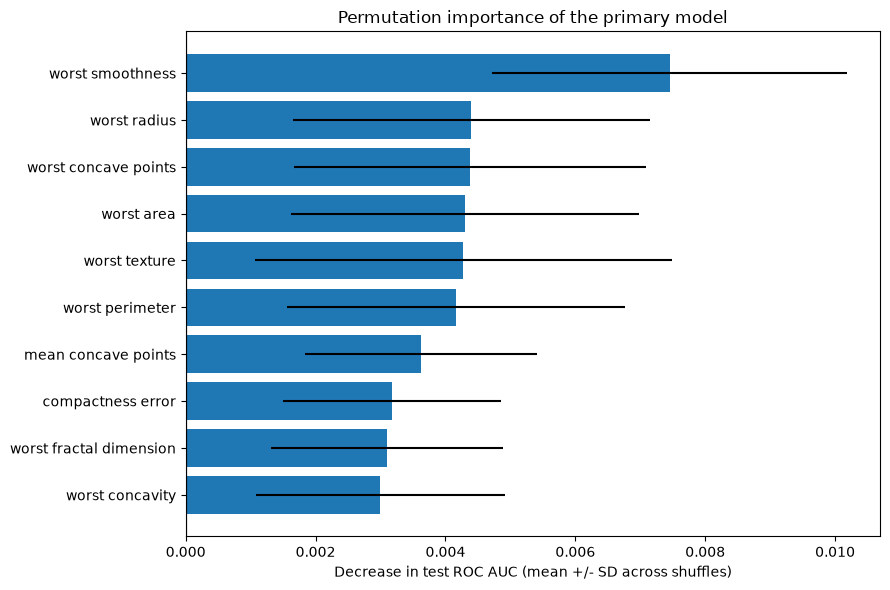

In [7]:
dataset = load_breast_cancer()
assert isinstance(dataset, Bunch)
feature_names = np.asarray(dataset.feature_names)

importance = permutation_importance(
    final_model, X_test, y_test,
    scoring=PRIMARY_METRIC, n_repeats=30,
    random_state=SEED, n_jobs=1,
)
order = np.argsort(importance.importances_mean)[::-1]

print("Permutation importance: test ROC AUC decrease")
for index in order[:10]:
    print(
        f"{feature_names[index]}: "
        f"{importance.importances_mean[index]:.5f} "
        f"+/- {importance.importances_std[index]:.5f}"
    )

plot_order = order[:10][::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    feature_names[plot_order], importance.importances_mean[plot_order],
    xerr=importance.importances_std[plot_order],
)
ax.set_xlabel("Decrease in test ROC AUC (mean +/- SD across shuffles)")
ax.set_title("Permutation importance of the primary model")
ax.axvline(0, color="black", linewidth=0.8)
fig.tight_layout()
plt.show()


## Wyniki
Największy średni spadek ROC AUC występował po przemieszaniu cech:
- worst smoothness: 0,00745
- worst radius: 0,00440
- worst concave points: 0,00438
- worst area: 0,00430
- worst texture: 0,00428

Oznacza to, że zaburzenie informacji zawartej w tych cechach najbardziej pogarszało zdolność modelu do rozróżniania klas w przeprowadzonym eksperymencie.

Warto zauważyć, że spadki ROC AUC po przemieszaniu poszczególnych cech były stosunkowo niewielkie. Nawet po zaburzeniu najważniejszej cechy (worst smoothness) ROC AUC wynosiło średnio około 0,99024.

Może to wynikać z tego, że model wykorzystuje informacje zawarte w wielu cechach jednocześnie, a część parametrów jest ze sobą skorelowana. Zaburzenie pojedynczej cechy nie musi więc znacząco pogarszać jakości modelu, ponieważ podobne informacje mogą być dostępne w innych cechach.

Nie oznacza to jednak, że poszczególne cechy są zbędne. Aby to sprawdzić, należałoby przeprowadzić dodatkowe eksperymenty z usuwaniem cech i ponownym trenowaniem modelu, oceniając wyniki za pomocą walidacji krzyżowej.

## Analiza korelacji cech

Jak widać powyżej, spadki ROC AUC po przemieszaniu cech były stosunkowo niewielkie. Może to wynikać z korelacji cech. W celu sprawdzenia, czy niewielkie spadki ROC AUC w analizie `permutation_importance` mogą wynikać z redundancji informacji, obliczono współczynniki korelacji Pearsona między wszystkimi 30 cechami na zbiorze treningowym.


In [8]:
correlation_matrix = np.corrcoef(X_train, rowvar=False)

correlations = []

for i in range(len(feature_names)):
    for j in range(i + 1, len(feature_names)):
        correlations.append((
            feature_names[i],
            feature_names[j],
            correlation_matrix[i, j],
        ))

correlations.sort(key=lambda x: abs(x[2]), reverse=True)

print("TOP 20 feature correlations:\n")

for a, b, r in correlations[:20]:
    print(f"{a:<25} vs {b:<25} r = {r:.3f}")


important_features = [
    "worst smoothness",
    "worst area",
    "worst texture",
    "mean perimeter",
    "mean concave points",
    "worst perimeter",
    "worst radius",
    "worst concave points",
]


for feature in important_features:
    i = np.where(feature_names == feature)[0][0]

    related = [
        (feature_names[j], correlation_matrix[i, j])
        for j in range(len(feature_names))
        if j != i
    ]

    related.sort(key=lambda x: abs(x[1]), reverse=True)

    print(f"\n{feature}:")
    for name, r in related[:3]:
        print(f"  {name:<25} r = {r:.3f}")


TOP 20 feature correlations:

mean radius               vs mean perimeter            r = 0.998
worst radius              vs worst perimeter           r = 0.993
mean radius               vs mean area                 r = 0.989
mean perimeter            vs mean area                 r = 0.988
worst radius              vs worst area                r = 0.986
worst perimeter           vs worst area                r = 0.979
mean perimeter            vs worst perimeter           r = 0.971
radius error              vs perimeter error           r = 0.971
mean radius               vs worst radius              r = 0.970
mean perimeter            vs worst radius              r = 0.970
mean radius               vs worst perimeter           r = 0.966
mean area                 vs worst radius              r = 0.963
mean area                 vs worst perimeter           r = 0.959
mean area                 vs worst area                r = 0.957
radius error              vs area error                r = 0

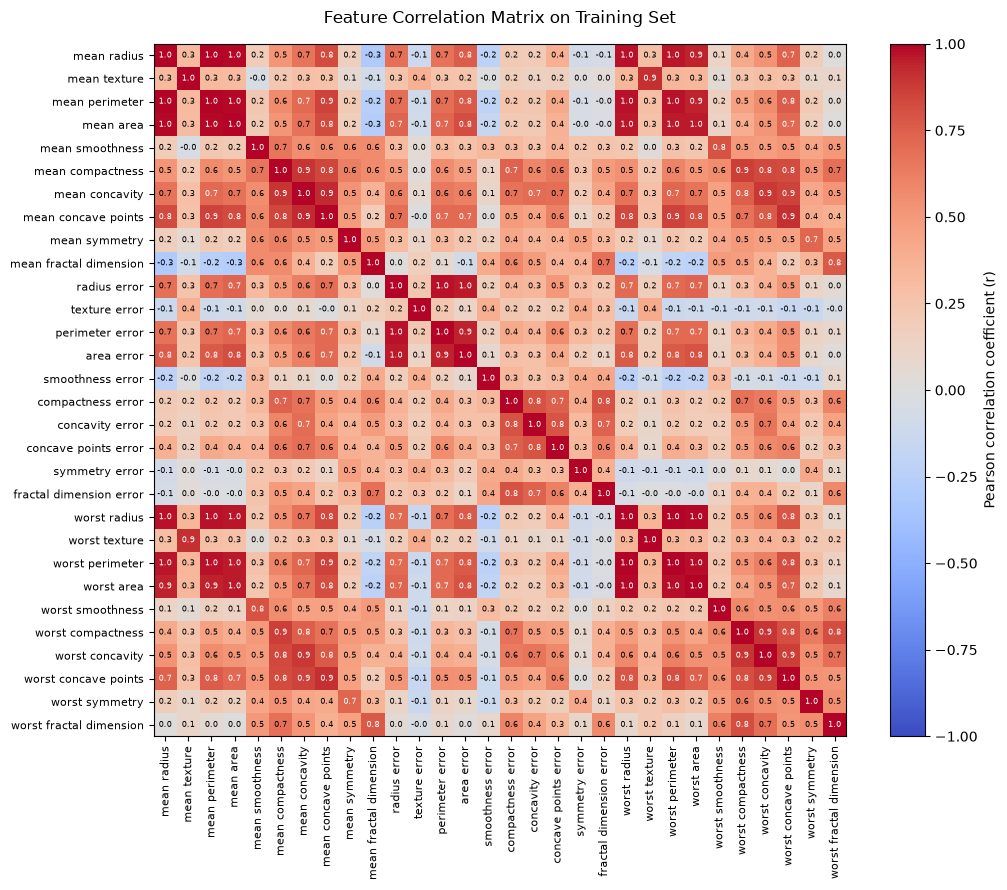

In [9]:
fig, ax = plt.subplots(figsize=(12,9))

im = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(np.arange(len(feature_names)))
ax.set_yticks(np.arange(len(feature_names)))

ax.set_xticklabels(feature_names, rotation=90, fontsize=8)
ax.set_yticklabels(feature_names, fontsize=8)

for i in range(len(feature_names)):
    for j in range(len(feature_names)):
        r = correlation_matrix[i, j]

        ax.text(
            j, i, f"{r:.1f}",
            ha="center",
            va="center",
            fontsize=6,
            color="white" if abs(r) >= 0.7 else "black"
        )

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Pearson correlation coefficient (r)")

ax.set_title("Feature Correlation Matrix on Training Set", pad=15)

plt.tight_layout()
plt.show()



## Wyniki 

Najsilniejsze dodatnie korelacje występowały między cechami:

- `mean radius` i `mean perimeter`: r = 0,998
- `worst radius` i `worst perimeter`: r = 0,993
- `mean radius` i `mean area`: r = 0,989
- `worst radius` i `worst area`: r = 0,986

Silne korelacje zaobserwowano również dla innych właściwości, np. `mean texture` i `worst texture` (r = 0,913) oraz `mean concave points` i `worst concave points` (r = 0,910).

Wszystkie pięć cech o największym znaczeniu według `permutation_importance` wykazywało stosunkowo silne korelacje z co najmniej jedną inną cechą.

Wyniki wskazują, że część parametrów zawiera podobne informacje. Może to częściowo wyjaśniać niewielkie spadki ROC AUC po przemieszaniu pojedynczych cech. Model nadal dysponuje innymi, silnie skorelowanymi parametrami.

Warto zauważyć, że `worst smoothness`, która powodowała największy średni spadek ROC AUC (0,00745), miała niższą maksymalną korelację z innymi cechami (r = 0,799) niż pozostałe cztery analizowane cechy. Jest to ciekawa obserwacja, ale nie pozwala jednoznacznie wyjaśnić jej większego znaczenia dla modelu.

Analiza korelacji stanowi także dodatkową przesłankę do rozważenia redukcji liczby cech. W walidacji krzyżowej model z 20 cechami uzyskał ROC AUC = 0,99525, a model wykorzystujący wszystkie 30 cech — 0,99536.

Silna korelacja nie oznacza jednak, że jedną z cech można usunąć bez pogorszenia jakości klasyfikacji. Wymagałoby to oceny odpowiednio zmodyfikowanych modeli w walidacji krzyżowej. Ponadto korelacja Pearsona opisuje wyłącznie liniowe zależności między parametrami.

## Czy trzeba mierzyć wszystkie cechy?

Aby ocenić, czy można ograniczyć liczbę cech, przeanalizowano wyniki GridSearchCV dla SVM przy różnych wartościach parametru k w SelectKBest.

Porównano średnie ROC AUC uzyskane dla 5, 10, 15, 20, 25 oraz wszystkich 30 cech. Zachowując stałe hiperparametry (`C=10`, `gamma=0.01`).

SVM FEATURE COUNT COMPARISON
C = 10, gamma = 0.01


1 FEATURES
  ROC AUC     : 0.96713
  Sensitivity : 85.29%
  Specificity : 93.33%

2 FEATURES
  ROC AUC     : 0.97276
  Sensitivity : 87.06%
  Specificity : 96.84%

3 FEATURES
  ROC AUC     : 0.98483
  Sensitivity : 90.00%
  Specificity : 96.14%

4 FEATURES
  ROC AUC     : 0.98607
  Sensitivity : 91.76%
  Specificity : 96.14%

5 FEATURES
  ROC AUC     : 0.98648
  Sensitivity : 92.35%
  Specificity : 95.79%

10 FEATURES
  ROC AUC     : 0.98627
  Sensitivity : 92.35%
  Specificity : 96.84%

15 FEATURES
  ROC AUC     : 0.98658
  Sensitivity : 91.76%
  Specificity : 95.79%

20 FEATURES
  ROC AUC     : 0.99525
  Sensitivity : 95.29%
  Specificity : 99.30%

25 FEATURES
  ROC AUC     : 0.99505
  Sensitivity : 95.29%
  Specificity : 98.95%

30 FEATURES
  ROC AUC     : 0.99536
  Sensitivity : 95.88%
  Specificity : 99.30%


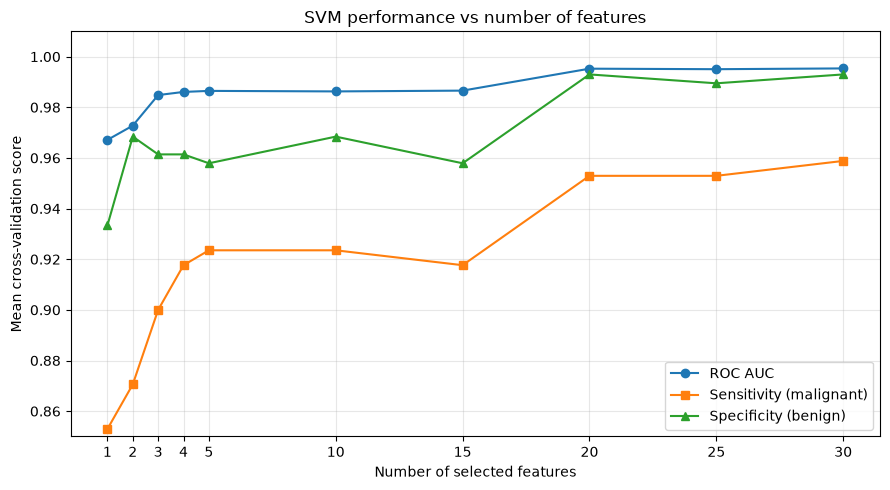

In [10]:

feature_names = np.asarray(load_breast_cancer().feature_names)

feature_results = []

scoring = {
    "roc_auc": "roc_auc",
    "sensitivity": make_scorer(recall_score, pos_label=0),
    "specificity": make_scorer(recall_score, pos_label=1),
}

print("SVM FEATURE COUNT COMPARISON")
print(
    f"C = {final_model.named_steps['svc'].C}, "
    f"gamma = {final_model.named_steps['svc'].gamma}\n"
)

for k in [1, 2, 3, 4, 5, 10, 15, 20, 25, 30]:
    model = clone(final_model)
    model.set_params(selectkbest__k=k)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring=scoring,
        n_jobs=1,
    )

    row = {
        "k": k,
        "roc_auc": scores["test_roc_auc"].mean(),
        "sensitivity": scores["test_sensitivity"].mean(),
        "specificity": scores["test_specificity"].mean(),
    }
    feature_results.append(row)


    print(f"\n{k} FEATURES")
    print(f"  ROC AUC     : {row['roc_auc']:.5f}")
    print(f"  Sensitivity : {row['sensitivity']:.2%}")
    print(f"  Specificity : {row['specificity']:.2%}")

counts = [r["k"] for r in feature_results]

plt.figure(figsize=(9, 5))

for key, label, marker in [
    ("roc_auc", "ROC AUC", "o"),
    ("sensitivity", "Sensitivity (malignant)", "s"),
    ("specificity", "Specificity (benign)", "^"),
]:
    plt.plot(
        counts,
        [r[key] for r in feature_results],
        marker=marker,
        label=label,
    )

plt.xticks(counts)
plt.ylim(0.85, 1.01)
plt.xlabel("Number of selected features")
plt.ylabel("Mean cross-validation score")
plt.title("SVM performance vs number of features")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()




## Wyniki

 Ocenę przeprowadzono za pomocą pięciokrotnej walidacji krzyżowej.

Najwyższy ROC AUC uzyskano dla 30 cech (0,99536), jednak model z 20 cechami osiągnął niemal identyczny wynik (0,99525).

Już przy 5 cechach ROC AUC wynosiło 0,98648, ale czułość (92,35%) i swoistość (95,79%) były niższe niż przy 30 cechach (odpowiednio 95,88% i 99,30%). Pokazuje to, że wysokie ROC AUC nie musi oznaczać równie wysokiej skuteczności klasyfikacji przy ustalonym progu.

Wyniki sugerują możliwość ograniczenia liczby cech do 20 bez dużego pogorszenia jakości. Może to częściowo wynikać z silnych korelacji między parametrami, wykazanych we wcześniejszej analizie. Mniej cech nie musi oznaczać mniej rzeczywistych pomiarów biologicznych.

## Czy większa ilość próbek poprawiłaby model?

Aby sprawdzić, czy model osiąga lepsze wyniki przy większej liczbie próbek, wykorzystujemy learning_curve, czyli krzywą uczenia. Porównujemy dwa wyniki:

- Training score: ROC AUC uzyskane na próbkach wykorzystanych do uczenia modelu.
- Validation score: ROC AUC uzyskane na próbkach niewykorzystanych do uczenia w danym foldzie.

Dzięki temu możemy sprawdzić, jak zwiększanie liczby próbek wpływa na zdolność modelu do rozróżniania klas oraz czy pojawiają się oznaki przeuczenia.


Learning curve
Samples: 72; training ROC AUC: 1.00000; validation ROC AUC: 0.99288
Samples: 145; training ROC AUC: 0.99980; validation ROC AUC: 0.99505
Samples: 218; training ROC AUC: 0.99877; validation ROC AUC: 0.99598
Samples: 291; training ROC AUC: 0.99829; validation ROC AUC: 0.99618
Samples: 364; training ROC AUC: 0.99830; validation ROC AUC: 0.99639


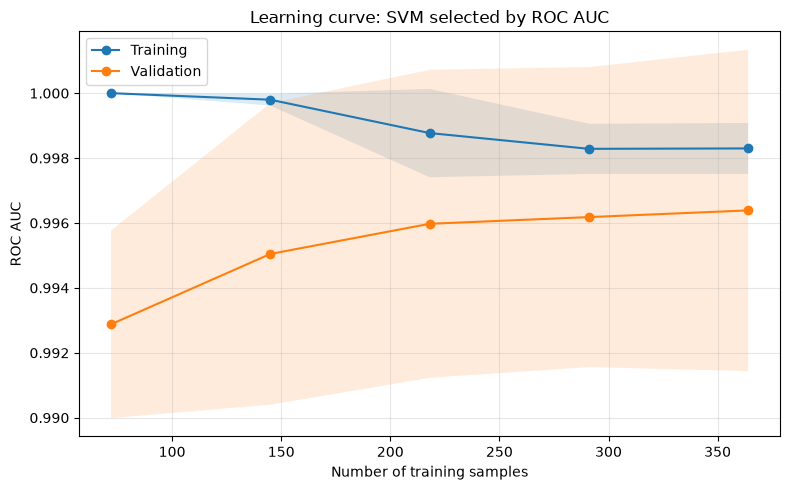

In [11]:
learning_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=SEED
)

train_sizes, train_scores, validation_scores = learning_curve(
    clone(final_model), X_train, y_train,
    train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0],
    cv=learning_cv, scoring=PRIMARY_METRIC,
    shuffle=True, random_state=SEED,
    n_jobs=1, error_score="raise",
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)

print("Learning curve")
for size, train_score, val_score in zip(train_sizes, train_mean, validation_mean):
    print(
        f"Samples: {size}; training ROC AUC: {train_score:.5f}; "
        f"validation ROC AUC: {val_score:.5f}"
    )
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(train_sizes, train_mean, "o-", label="Training")
ax.plot(train_sizes, validation_mean, "o-", label="Validation")
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)
ax.fill_between(
    train_sizes, validation_mean - validation_std,
    validation_mean + validation_std, alpha=0.15,
)
ax.set_xlabel("Number of training samples")
ax.set_ylabel("ROC AUC")
ax.set_title("Learning curve: SVM selected by ROC AUC")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


## Wyniki

Przy 72 próbkach model uzyskał ROC AUC równe 1,00000 na treningu i 0,99288 na walidacji. Oznacza to, że już przy stosunkowo małym zbiorze bardzo dobrze rozróżniał obie klasy.

Wraz ze zwiększaniem liczby próbek wynik walidacyjny stopniowo wzrastał, osiągając 0,99639 przy 364 próbkach. Wynik treningowy w tym punkcie wyniósł 0,99830.

Obie krzywe są blisko siebie, co nie wskazuje na silne przeuczenie modelu. Jednocześnie wyniki zaczynają się stabilizować, więc korzyści z dodawania kolejnych próbek mogą być ograniczone.

Nie można jednak zagwarantować, że większy zbiór danych poprawi skuteczność. Zależy to również od jakości i różnorodności nowych próbek.
